In [1]:
from google.colab import drive, runtime
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd '/content/drive/MyDrive/Applied AI Researcher Roadmap/Pytorch/attention'

/content/drive/MyDrive/Applied AI Researcher Roadmap/Pytorch/attention


In [3]:
import torch
from torch import nn
from torch.nn.functional import softmax
import pandas as pd
from math import sqrt

# Creating pre-layer-norm Transformer block

In [ ]:
class PreLayerNormTransformer(nn.Module):
  def __init__(self, num_heads, emb_dim):
    super().__init__()
    # For MHA
    self.num_heads = num_heads
    if emb_dim % num_heads != 0:
      raise ValueError("This will cause shape issue when mha result is added to X. change emb_dim and num_heads")
    self.dq = emb_dim // num_heads
    self.layerNorm1 = nn.LayerNorm(emb_dim)
    self.Wq = nn.Linear(emb_dim, emb_dim)
    self.Wk = nn.Linear(emb_dim, emb_dim)
    self.Wv = nn.Linear(emb_dim, emb_dim)
    self.Wo = nn.Linear(emb_dim, emb_dim)
    self.layerNorm2 = nn.LayerNorm(emb_dim)

    # For FFN
    self.linear1 = nn.Linear(emb_dim, emb_dim*4)
    self.gelu = nn.GELU()
    self.linear2 = nn.Linear(emb_dim*4, emb_dim)

  def mha(self, X, mask):
    Q = self.Wq(X)
    K = self.Wk(X)
    V = self.Wv(X)

    Q = Q.reshape(X.shape[0], X.shape[1], self.num_heads, self.dq).transpose(1, 2)
    K = K.reshape(X.shape[0], X.shape[1], self.num_heads, self.dq).transpose(1, 2)
    V = V.reshape(X.shape[0], X.shape[1], self.num_heads, self.dq).transpose(1, 2)

    dot_prod = Q @ K.transpose(2, 3)
    scaled_dot = dot_prod / sqrt(self.dq)
    scaled_dot = scaled_dot.masked_fill(~mask[:, None, None, :], float('-inf'))

    scores = softmax(scaled_dot, dim=-1)
    values = scores @ V
    values = values.transpose(1, 2).reshape(X.shape[0], X.shape[1], X.shape[2])

    values = self.Wo(values)
    values = values.masked_fill(
        ~mask[:, :, None],
        0.0
    )
    assert values.shape == X.shape
    assert torch.isfinite(values).all()

    # The attention branch must be zero at padded query positions.
    padded = values.masked_select(~mask[:, :, None].expand_as(values))
    assert torch.allclose(padded, torch.zeros_like(padded))

    return (X + values).masked_fill(
        ~mask[:, :, None],
        0.0
    )

  def ffn(self, H):
    H1 = self.layerNorm2(H)
    H1 = self.linear1(H1)
    H1 = self.gelu(H1)
    H1 = self.linear2(H1)
    return H + H1

  def forward(self, X, mask):
    H = self.mha(self.layerNorm1(X), mask)
    Y = self.ffn(H).masked_fill(
        ~mask[:, :, None],
        0.0
    )
    return Y

In [ ]:
X = torch.rand((10, 300, 100))

In [ ]:
X

tensor([[[0.0469, 0.3949, 0.3247,  ..., 0.7907, 0.9563, 0.6584],
         [0.7268, 0.5691, 0.2194,  ..., 0.1971, 0.1872, 0.7328],
         [0.7719, 0.8232, 0.7930,  ..., 0.8161, 0.4996, 0.9617],
         ...,
         [0.6277, 0.8961, 0.4920,  ..., 0.1849, 0.4033, 0.4159],
         [0.9830, 0.4618, 0.8580,  ..., 0.3113, 0.1941, 0.1731],
         [0.7915, 0.6649, 0.3250,  ..., 0.8494, 0.8937, 0.6876]],

        [[0.2590, 0.6641, 0.7808,  ..., 0.3465, 0.3476, 0.3470],
         [0.7071, 0.4686, 0.2611,  ..., 0.3504, 0.5647, 0.8797],
         [0.7588, 0.5104, 0.6386,  ..., 0.3783, 0.8148, 0.4527],
         ...,
         [0.0354, 0.5815, 0.5515,  ..., 0.6838, 0.7164, 0.4139],
         [0.0785, 0.6461, 0.1702,  ..., 0.7483, 0.5616, 0.8157],
         [0.2790, 0.9046, 0.0341,  ..., 0.6930, 0.7105, 0.5965]],

        [[0.8885, 0.1580, 0.3542,  ..., 0.3701, 0.2427, 0.6982],
         [0.0653, 0.6226, 0.9627,  ..., 0.4290, 0.8660, 0.3890],
         [0.6394, 0.3621, 0.0331,  ..., 0.5921, 0.9583, 0.

In [ ]:
import random

mask = []

for i in range(X.shape[0]):
  s = random.randint(1, X.shape[1] - 1)

  m = torch.tensor([True] * s + [False] * (X.shape[1] - s))

  mask.append(m)

mask = torch.stack(mask)

In [ ]:
mask[:, None, :, None].shape

torch.Size([10, 1, 300, 1])

In [ ]:
model = PreLayerNormTransformer(4, 100)

In [ ]:
mask

tensor([[ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        ...,
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False]])

In [ ]:
y = model(X, mask)

### Tests

In [ ]:
Y = model(X, mask)

assert Y.shape == X.shape
assert torch.isfinite(Y).all()

loss = Y.square().mean()
loss.backward()

for name, parameter in model.named_parameters():
    assert parameter.grad is not None, f"No gradient: {name}"
    assert torch.isfinite(parameter.grad).all(), f"Invalid gradient: {name}"

In [ ]:
Y.shape

torch.Size([10, 10, 300, 100])

In [ ]:
X.shape

torch.Size([10, 300, 100])

- Verified: the tested tensor shapes, finite outputs, and padded-query masking invariant.
- Still to verify: padded keys receive zero attention probability, valid query rows sum to 1, and gradients flow through the complete Transformer block.
- Architectural status: your pre-LN structure is correct, provided you use 96-dimensional Q/K/V projections with Wo mapping \(96\rightarrow100\).

# Positional Encoding

In [ ]:
2*torch.arange(0, 50, 2)

tensor([ 0,  4,  8, 12, 16, 20, 24, 28, 32, 36, 40, 44, 48, 52, 56, 60, 64, 68,
        72, 76, 80, 84, 88, 92, 96])

In [ ]:
(10000**(2 * torch.arange(0, 50, 2)/50))

tensor([1.0000e+00, 2.0893e+00, 4.3652e+00, 9.1201e+00, 1.9055e+01, 3.9811e+01,
        8.3176e+01, 1.7378e+02, 3.6308e+02, 7.5858e+02, 1.5849e+03, 3.3113e+03,
        6.9183e+03, 1.4454e+04, 3.0200e+04, 6.3096e+04, 1.3183e+05, 2.7542e+05,
        5.7544e+05, 1.2023e+06, 2.5119e+06, 5.2481e+06, 1.0965e+07, 2.2909e+07,
        4.7863e+07])

In [ ]:
(torch.arange(0, 120).unsqueeze(dim=1)/(10000**(2 * torch.arange(0, 50, 2)/50)))

tensor([[0.0000e+00, 0.0000e+00, 0.0000e+00,  ..., 0.0000e+00, 0.0000e+00,
         0.0000e+00],
        [1.0000e+00, 4.7863e-01, 2.2909e-01,  ..., 9.1201e-08, 4.3652e-08,
         2.0893e-08],
        [2.0000e+00, 9.5726e-01, 4.5817e-01,  ..., 1.8240e-07, 8.7303e-08,
         4.1786e-08],
        ...,
        [1.1700e+02, 5.6000e+01, 2.6803e+01,  ..., 1.0671e-05, 5.1072e-06,
         2.4445e-06],
        [1.1800e+02, 5.6478e+01, 2.7032e+01,  ..., 1.0762e-05, 5.1509e-06,
         2.4654e-06],
        [1.1900e+02, 5.6957e+01, 2.7261e+01,  ..., 1.0853e-05, 5.1945e-06,
         2.4863e-06]])

In [ ]:
(torch.arange(0, 120).unsqueeze(dim=1)/(10000**(4 * torch.arange(0, 50)/50))).shape

torch.Size([120, 50])

In [ ]:
torch.zeros(100, 50)[:, 0::2].shape

torch.Size([100, 25])

In [4]:
class PositionalEncoding(nn.Module):
  def __init__(self, seq_len, emb_dim, n=10000):
    super().__init__()
    self.pos = torch.arange(0, seq_len).unsqueeze(dim=1)
    self.seq_len = seq_len
    self.emb_dim = emb_dim
    self.n = n
    val = self.pos/(self.n**(2*torch.arange(0, self.emb_dim, 2)/self.emb_dim))

    pe = torch.zeros(self.seq_len, self.emb_dim)
    pe[:, 0::2] = torch.sin(val)
    pe[:, 1::2] = torch.cos(val)

    self.register_buffer('pe', pe)

  def forward(self, X):
    X = X + self.pe.unsqueeze(dim=0)
    return X

### Testing positional encoding

In [ ]:
pe_model = PositionalEncoding(300, 100)

In [ ]:
pe_model

PositionalEncoding()

In [ ]:
X1, pe = pe_model(X)

RuntimeError: The size of tensor a (8) must match the size of tensor b (100) at non-singleton dimension 2

In [ ]:
X1.shape

torch.Size([3, 5, 8])

In [ ]:
pe.unsqueeze(dim=0).shape

torch.Size([1, 5, 8])

In [ ]:
import matplotlib.pyplot as plt

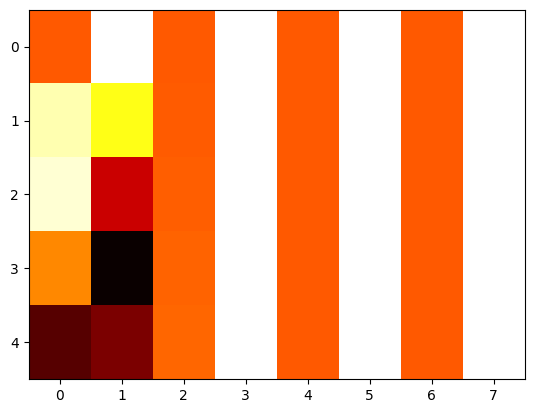

In [ ]:
plt.imshow(pe, aspect='auto')

In [ ]:
(X1[0] - X[0]).shape

torch.Size([5, 8])

In [ ]:
pe.dtype

torch.float32

In [ ]:
(X1[0] - X[0]).dtype

torch.float32

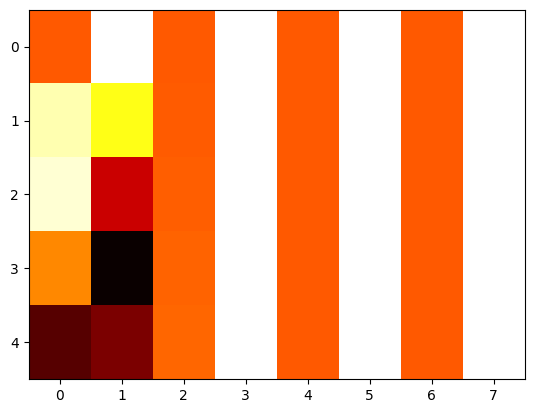

In [ ]:
plt.imshow(X1[0] - X[0], aspect='auto')

In [ ]:
X = torch.randn(3, 5, 8)

positional_encoding = PositionalEncoding(
    seq_len=5,
    emb_dim=8
)

X1, pe = positional_encoding(X)

assert X1.shape == X.shape
assert pe.shape == (5, 8)

assert torch.allclose(X1[0] - X[0], pe, atol=1e-6)
assert torch.allclose(X1[1] - X[1], pe, atol=1e-6)
assert torch.allclose(X1[2] - X[2], pe, atol=1e-6)

In [ ]:
X = torch.randn(3, 5, 8)

model = PositionalEncoding(seq_len=5, emb_dim=8)

X1, pe = model(X)

print("X shape:", X.shape)
print("X1 shape:", X1.shape)
print("PE shape:", pe.shape)

print("Difference:")
print(X1[0] - X[0])

print("PE:")
print(pe)

print("Allclose:", torch.allclose(X1[0] - X[0], pe, atol=1e-6))

X shape: torch.Size([3, 5, 8])
X1 shape: torch.Size([3, 5, 8])
PE shape: torch.Size([5, 8])
Difference:
tensor([[ 0.0000e+00,  1.0000e+00,  0.0000e+00,  1.0000e+00,  0.0000e+00,
          1.0000e+00,  0.0000e+00,  1.0000e+00],
        [ 8.4147e-01,  5.4030e-01,  9.9998e-03,  9.9995e-01,  1.0002e-04,
          1.0000e+00,  9.5367e-07,  1.0000e+00],
        [ 9.0930e-01, -4.1615e-01,  1.9999e-02,  9.9980e-01,  2.0000e-04,
          1.0000e+00,  1.9968e-06,  1.0000e+00],
        [ 1.4112e-01, -9.8999e-01,  2.9996e-02,  9.9955e-01,  2.9999e-04,
          1.0000e+00,  3.0026e-06,  1.0000e+00],
        [-7.5680e-01, -6.5364e-01,  3.9989e-02,  9.9920e-01,  4.0001e-04,
          1.0000e+00,  3.9935e-06,  1.0000e+00]])
PE:
tensor([[ 0.0000e+00,  1.0000e+00,  0.0000e+00,  1.0000e+00,  0.0000e+00,
          1.0000e+00,  0.0000e+00,  1.0000e+00],
        [ 8.4147e-01,  5.4030e-01,  9.9998e-03,  9.9995e-01,  1.0000e-04,
          1.0000e+00,  1.0000e-06,  1.0000e+00],
        [ 9.0930e-01, -4.1615e

# Incorporating positional encoding to prelayernorm

In [5]:
class PreLayerNormTransformerWithPE(nn.Module):
  def __init__(self, vocab_size, num_heads, seq_len, emb_dim):
    super().__init__()
    # For embeddings
    self.embedding_layer = nn.Embedding(vocab_size, emb_dim)

    # For Positional Encoding
    self.pe = PositionalEncoding(seq_len, emb_dim)

    # For MHA
    self.num_heads = num_heads
    if emb_dim % num_heads != 0:
      raise ValueError("This will cause shape issue when mha result is added to X. change emb_dim and num_heads")
    self.dq = emb_dim // num_heads
    self.layerNorm1 = nn.LayerNorm(emb_dim)
    self.Wq = nn.Linear(emb_dim, emb_dim)
    self.Wk = nn.Linear(emb_dim, emb_dim)
    self.Wv = nn.Linear(emb_dim, emb_dim)
    self.Wo = nn.Linear(emb_dim, emb_dim)
    self.layerNorm2 = nn.LayerNorm(emb_dim)

    # For FFN
    self.linear1 = nn.Linear(emb_dim, emb_dim*4)
    self.gelu = nn.GELU()
    self.linear2 = nn.Linear(emb_dim*4, emb_dim)

    # For output projection
    self.output_proj = nn.Linear(emb_dim, 1)

  def mha(self, X, mask):
    Q = self.Wq(X)
    K = self.Wk(X)
    V = self.Wv(X)

    Q = Q.reshape(X.shape[0], X.shape[1], self.num_heads, self.dq).transpose(1, 2)
    K = K.reshape(X.shape[0], X.shape[1], self.num_heads, self.dq).transpose(1, 2)
    V = V.reshape(X.shape[0], X.shape[1], self.num_heads, self.dq).transpose(1, 2)

    dot_prod = Q @ K.transpose(2, 3)
    scaled_dot = dot_prod / sqrt(self.dq)
    scaled_dot = scaled_dot.masked_fill(~mask[:, None, None, :], float('-inf'))

    scores = softmax(scaled_dot, dim=-1)
    values = scores @ V
    values = values.transpose(1, 2).reshape(X.shape[0], X.shape[1], X.shape[2])

    values = self.Wo(values)
    values = values.masked_fill(
        ~mask[:, :, None],
        0.0
    )
    assert values.shape == X.shape
    assert torch.isfinite(values).all()

    # The attention branch must be zero at padded query positions.
    padded = values.masked_select(~mask[:, :, None].expand_as(values))
    assert torch.allclose(padded, torch.zeros_like(padded))

    return (X + values).masked_fill(
        ~mask[:, :, None],
        0.0
    )

  def ffn(self, H):
    H1 = self.layerNorm2(H)
    H1 = self.linear1(H1)
    H1 = self.gelu(H1)
    H1 = self.linear2(H1)
    return H + H1

  def forward(self, X, mask):
    X1 = self.embedding_layer(X)
    X1 = self.pe(X1)
    X1 = X1.masked_fill(
        ~mask[:, :, None],
        0.0
    )
    H = self.mha(self.layerNorm1(X1), mask)
    Y = self.ffn(H).masked_fill(
        ~mask[:, :, None],
        0.0
    )
    Y_pooled = Y.sum(dim=1) / mask.sum(dim=1, keepdim=True)

    Y = self.output_proj(Y_pooled)
    return Y

In [6]:
class PreLayerNormTransformerWithoutPE(nn.Module):
  def __init__(self, vocab_size, num_heads, seq_len, emb_dim):
    super().__init__()
    # For embeddings
    self.embedding_layer = nn.Embedding(vocab_size, emb_dim)

    # For MHA
    self.num_heads = num_heads
    if emb_dim % num_heads != 0:
      raise ValueError("This will cause shape issue when mha result is added to X. change emb_dim and num_heads")
    self.dq = emb_dim // num_heads
    self.layerNorm1 = nn.LayerNorm(emb_dim)
    self.Wq = nn.Linear(emb_dim, emb_dim)
    self.Wk = nn.Linear(emb_dim, emb_dim)
    self.Wv = nn.Linear(emb_dim, emb_dim)
    self.Wo = nn.Linear(emb_dim, emb_dim)
    self.layerNorm2 = nn.LayerNorm(emb_dim)

    # For FFN
    self.linear1 = nn.Linear(emb_dim, emb_dim*4)
    self.gelu = nn.GELU()
    self.linear2 = nn.Linear(emb_dim*4, emb_dim)

    # For output projection
    self.output_proj = nn.Linear(emb_dim, 1)

  def mha(self, X, mask):
    Q = self.Wq(X)
    K = self.Wk(X)
    V = self.Wv(X)

    Q = Q.reshape(X.shape[0], X.shape[1], self.num_heads, self.dq).transpose(1, 2)
    K = K.reshape(X.shape[0], X.shape[1], self.num_heads, self.dq).transpose(1, 2)
    V = V.reshape(X.shape[0], X.shape[1], self.num_heads, self.dq).transpose(1, 2)

    dot_prod = Q @ K.transpose(2, 3)
    scaled_dot = dot_prod / sqrt(self.dq)
    scaled_dot = scaled_dot.masked_fill(~mask[:, None, None, :], float('-inf'))

    scores = softmax(scaled_dot, dim=-1)
    values = scores @ V
    values = values.transpose(1, 2).reshape(X.shape[0], X.shape[1], X.shape[2])

    values = self.Wo(values)
    values = values.masked_fill(
        ~mask[:, :, None],
        0.0
    )
    assert values.shape == X.shape
    assert torch.isfinite(values).all()

    # The attention branch must be zero at padded query positions.
    padded = values.masked_select(~mask[:, :, None].expand_as(values))
    assert torch.allclose(padded, torch.zeros_like(padded))

    return (X + values).masked_fill(
        ~mask[:, :, None],
        0.0
    )

  def ffn(self, H):
    H1 = self.layerNorm2(H)
    H1 = self.linear1(H1)
    H1 = self.gelu(H1)
    H1 = self.linear2(H1)
    return H + H1

  def forward(self, X, mask):
    X1 = self.embedding_layer(X)
    X1 = X1.masked_fill(
        ~mask[:, :, None],
        0.0
    )
    H = self.mha(self.layerNorm1(X1), mask)
    Y = self.ffn(H).masked_fill(
        ~mask[:, :, None],
        0.0
    )
    Y_pooled = Y.sum(dim=1) / mask.sum(dim=1, keepdim=True)

    Y = self.output_proj(Y_pooled)
    return Y

### Tests

In [ ]:
model = PreLayerNormTransformerWithPE(4, X.shape[1] ,100)

NameError: name 'PreLayerNormTransformerwithPE' is not defined

In [ ]:
mask

tensor([[ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        ...,
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False]])

In [ ]:
y1 = model(X, mask)

In [ ]:
y - y1

tensor([[[ 0.1592, -1.3994,  0.7566,  ..., -0.2393,  1.4368,  0.0927],
         [ 0.1352, -0.2875, -1.0238,  ..., -1.5497,  0.1249,  0.4247],
         [ 0.2867,  1.9794, -0.1144,  ..., -0.6226,  0.5769,  0.6749],
         ...,
         [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000]],

        [[ 0.4408, -1.1405,  1.6186,  ..., -1.3450,  0.6613, -0.9258],
         [-0.2350, -0.1818, -0.6784,  ..., -1.3927,  0.7123,  0.0675],
         [ 0.0570,  1.3951, -0.5290,  ..., -1.2835,  1.6701, -0.6847],
         ...,
         [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000]],

        [[ 1.5325, -1.6063,  0.4070,  ..., -1.0747,  0.4434, -0.2344],
         [-1.2679, -0.0892,  0.4908,  ..., -0

In [ ]:
Y = model(X, mask)

assert Y.shape == X.shape
assert torch.isfinite(Y).all()

loss = Y.square().mean()
loss.backward()

for name, parameter in model.named_parameters():
    assert parameter.grad is not None, f"No gradient: {name}"
    assert torch.isfinite(parameter.grad).all(), f"Invalid gradient: {name}"

In [ ]:
Y.shape

torch.Size([10, 10, 300, 100])

In [ ]:
X.shape

torch.Size([10, 300, 100])

- Verified: the tested tensor shapes, finite outputs, and padded-query masking invariant.
- Still to verify: padded keys receive zero attention probability, valid query rows sum to 1, and gradients flow through the complete Transformer block.
- Architectural status: your pre-LN structure is correct, provided you use 96-dimensional Q/K/V projections with Wo mapping \(96\rightarrow100\).

# Toy Experiments

## Predict if the 1st and last token in a sequence are the same.

Compare 2 transformer blocks, one with PE and one without, and check how they perform at classifying sequences based on whether the 1st and last tokens are the same or not

#### Data Generation

In [ ]:
vocabulary = list(range(20))

In [ ]:
vocabulary

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]

In [ ]:
import random

In [ ]:
[1, 2, 3] + [0]*10

[1, 2, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

In [ ]:
import random
import torch

random.seed(42)
torch.manual_seed(42)

num_pairs = 4000
seq_len = 20
vocab_size = 21
PAD = 20

sequences = torch.full(
    (num_pairs * 2, seq_len),
    PAD,
    dtype=torch.long
)

mask = torch.zeros(
    (num_pairs * 2, seq_len),
    dtype=torch.bool
)

y = torch.zeros(
    (num_pairs * 2, 1),
    dtype=torch.float32
)

for j in range(num_pairs):

    l = random.randint(3, 19)

    # Select two distinct tokens
    a, b = random.sample(range(20), 2)

    # Generate the shared middle tokens
    middle = [
        random.randint(0, 19)
        for _ in range(l - 2)
    ]

    # Positive sequence: first == last
    positive = [a] + middle + [a]

    # Negative sequence: first != last
    # Same tokens, different ordering
    negative = [a] + middle + [b]

    idx_pos = 2 * j
    idx_neg = 2 * j + 1

    sequences[idx_pos, :l] = torch.tensor(positive)
    sequences[idx_neg, :l] = torch.tensor(negative)

    mask[idx_pos, :l] = True
    mask[idx_neg, :l] = True

    y[idx_pos] = 1.0
    y[idx_neg] = 0.0

In [ ]:
sequences = sequences.to(torch.int32)

In [ ]:
sequences.shape

torch.Size([8000, 20])

In [ ]:
mask = mask.to(torch.bool)

In [ ]:
y

tensor([[1.],
        [0.],
        [1.],
        ...,
        [0.],
        [1.],
        [0.]])

In [ ]:
y.shape

torch.Size([8000, 1])

In [ ]:
(y == 1).sum()

tensor(4000)

In [ ]:
# Shuffle pair indices
pair_indices = torch.randperm(
    num_pairs,
    generator=torch.Generator().manual_seed(42)
)

test_pairs = pair_indices[:200]
val_pairs = pair_indices[200:400]
train_pairs = pair_indices[400:]


def expand_pairs(pair_indices):
    return torch.stack(
        [2 * pair_indices, 2 * pair_indices + 1],
        dim=1
    ).flatten()


train_idx = expand_pairs(train_pairs)
val_idx = expand_pairs(val_pairs)
test_idx = expand_pairs(test_pairs)


# Create datasets
X_train = sequences[train_idx]
mask_train = mask[train_idx]
y_train = y[train_idx]

X_val = sequences[val_idx]
mask_val = mask[val_idx]
y_val = y[val_idx]

X_test = sequences[test_idx]
mask_test = mask[test_idx]
y_test = y[test_idx]

In [ ]:
for name, X, M, Y in [
    ("Train", X_train, mask_train, y_train),
    ("Validation", X_val, mask_val, y_val),
    ("Test", X_test, mask_test, y_test)
]:
    print(f"\n{name}")
    print("X:", X.shape)
    print("Mask:", M.shape)
    print("Y:", Y.shape)
    print("Positive:", (Y == 1).sum().item())
    print("Negative:", (Y == 0).sum().item())


Train
X: torch.Size([7200, 20])
Mask: torch.Size([7200, 20])
Y: torch.Size([7200, 1])
Positive: 3600
Negative: 3600

Validation
X: torch.Size([400, 20])
Mask: torch.Size([400, 20])
Y: torch.Size([400, 1])
Positive: 200
Negative: 200

Test
X: torch.Size([400, 20])
Mask: torch.Size([400, 20])
Y: torch.Size([400, 1])
Positive: 200
Negative: 200


In [ ]:
X_train.shape

torch.Size([7200, 20])

### Saving data

In [ ]:
data = {
    "X_train": X_train,
    "X_test": X_test,
    "X_val": X_val,
    "y_train": y_train,
    "y_test": y_test,
    "y_val": y_val,
    "mask_train": mask_train,
    "mask_test": mask_test,
    "mask_val": mask_val
}

In [ ]:
torch.save(data, "Experiment1/data.pt")

In [9]:
data = torch.load("Experiment1/data.pt")

In [10]:
data

{'X_train': tensor([[ 2, 16, 13,  ..., 20, 20, 20],
         [ 2, 16, 13,  ..., 20, 20, 20],
         [ 7, 12,  6,  ..., 20, 20, 20],
         ...,
         [ 8, 14,  9,  ..., 16, 20, 20],
         [ 6,  9,  7,  ..., 20, 20, 20],
         [ 6,  9,  7,  ..., 20, 20, 20]], dtype=torch.int32),
 'X_test': tensor([[12,  8,  2,  ..., 20, 20, 20],
         [12,  8,  2,  ..., 20, 20, 20],
         [ 0, 16,  7,  ..., 20, 20, 20],
         ...,
         [17, 18, 11,  ..., 20, 20, 20],
         [ 4, 10,  2,  ..., 20, 20, 20],
         [ 4, 10,  2,  ..., 20, 20, 20]], dtype=torch.int32),
 'X_val': tensor([[ 8,  8, 15,  ...,  5,  8, 20],
         [ 8,  8, 15,  ...,  5,  4, 20],
         [ 0, 16,  0,  ..., 20, 20, 20],
         ...,
         [14,  3,  4,  ..., 20, 20, 20],
         [14,  5, 14,  ..., 20, 20, 20],
         [14,  5, 14,  ..., 20, 20, 20]], dtype=torch.int32),
 'y_train': tensor([[1.],
         [0.],
         [1.],
         ...,
         [0.],
         [1.],
         [0.]]),
 'y_test':

In [11]:
X_train = data['X_train']
X_val = data['X_val']
X_test = data['X_test']
y_train = data['y_train']
y_val = data['y_val']
y_test = data['y_test']
mask_train = data['mask_train']
mask_val = data['mask_val']
mask_test = data['mask_test']


### Training

In [22]:
model1 = PreLayerNormTransformerWithPE(21, 4, 20, 80)

state = model1.state_dict()

lr = 0.001
optimizer = torch.optim.Adam(model1.parameters(), lr=lr)
loss = torch.nn.BCEWithLogitsLoss()

for i in range(200):
  model1.train()
  y1 = model1(X_train, mask_train)
  l = loss(y1, y_train)

  optimizer.zero_grad()
  l.backward()
  optimizer.step()

  preds = (y1 >= 0).float()
  accuracy = (preds == y_train).float().mean()

  model1.eval()
  with torch.no_grad():
    y2 = model1(X_val, mask_val)
    l_val = loss(y2, y_val)
    preds2 = (y2 >= 0.5).float()
    accuracy2 = (preds2 == y_val).float().mean()

  print(f"Epoch: {i+1} -> Loss: {l.item()}, Accuracy {accuracy.item()}, Val Loss: {l_val.item()}, Val Accuracy {accuracy2.item()}")

Epoch: 1 -> Loss: 0.7074906229972839, Accuracy 0.48597222566604614, Val Loss: 0.7008165717124939, Val Accuracy 0.5
Epoch: 2 -> Loss: 0.7045022249221802, Accuracy 0.5151388645172119, Val Loss: 0.7004776000976562, Val Accuracy 0.5
Epoch: 3 -> Loss: 0.7035695910453796, Accuracy 0.5134721994400024, Val Loss: 0.6945722103118896, Val Accuracy 0.5
Epoch: 4 -> Loss: 0.6969772577285767, Accuracy 0.5130555629730225, Val Loss: 0.6945664286613464, Val Accuracy 0.5
Epoch: 5 -> Loss: 0.696383535861969, Accuracy 0.48847222328186035, Val Loss: 0.6969308257102966, Val Accuracy 0.5
Epoch: 6 -> Loss: 0.6983189582824707, Accuracy 0.4893055558204651, Val Loss: 0.696205735206604, Val Accuracy 0.5
Epoch: 7 -> Loss: 0.6972877979278564, Accuracy 0.49069443345069885, Val Loss: 0.6938496232032776, Val Accuracy 0.5
Epoch: 8 -> Loss: 0.694663405418396, Accuracy 0.4933333396911621, Val Loss: 0.6930013298988342, Val Accuracy 0.5
Epoch: 9 -> Loss: 0.6935345530509949, Accuracy 0.5098611116409302, Val Loss: 0.694112420

In [23]:
model2 = PreLayerNormTransformerWithoutPE(21, 4, 20, 80)
model2.load_state_dict({
    k: v for k, v in state.items()
    if k in model2.state_dict()
})

lr2 = 0.001
optimizer2 = torch.optim.Adam(model2.parameters(), lr=lr2)
loss2 = torch.nn.BCEWithLogitsLoss()

for i in range(200):
  model2.train()
  y3 = model2(X_train, mask_train)
  l = loss2(y3, y_train)

  optimizer2.zero_grad()
  l.backward()
  optimizer2.step()
  pred = (y3 >= 0).float()
  acc = (pred == y_train).float().mean()

  model2.eval()
  with torch.no_grad():
    y4 = model2(X_val, mask_val)
    l_val = loss2(y4, y_val)
    pred3 = (y4 >= 0).float()
    acc3 = (pred3 == y_val).float().mean()

  print(f"Epoch: {i+1} -> Loss: {l.item()}, Accuracy {acc.item()}, Val Loss: {l_val.item()}, Val Accuracy {acc3.item()}")

Epoch: 1 -> Loss: 11.347979545593262, Accuracy 0.49986112117767334, Val Loss: 6.265721321105957, Val Accuracy 0.5
Epoch: 2 -> Loss: 6.314138412475586, Accuracy 0.5008333325386047, Val Loss: 2.842262029647827, Val Accuracy 0.5199999809265137
Epoch: 3 -> Loss: 2.996159315109253, Accuracy 0.523472249507904, Val Loss: 1.7910417318344116, Val Accuracy 0.5249999761581421
Epoch: 4 -> Loss: 2.0584003925323486, Accuracy 0.5363888740539551, Val Loss: 2.1062331199645996, Val Accuracy 0.5274999737739563
Epoch: 5 -> Loss: 2.2506518363952637, Accuracy 0.5329166650772095, Val Loss: 2.4214327335357666, Val Accuracy 0.5149999856948853
Epoch: 6 -> Loss: 2.4468321800231934, Accuracy 0.534583330154419, Val Loss: 2.4890172481536865, Val Accuracy 0.5224999785423279
Epoch: 7 -> Loss: 2.4523708820343018, Accuracy 0.5311111211776733, Val Loss: 2.3607726097106934, Val Accuracy 0.5199999809265137
Epoch: 8 -> Loss: 2.2987663745880127, Accuracy 0.5288888812065125, Val Loss: 2.1060848236083984, Val Accuracy 0.51749

In [24]:
logits_1 = model1(X_train, mask_train)
pred_1 = (logits_1 >= 0).float()
acc_1 = (pred_1 == y_train).float().mean()

logits_2 = model2(X_train, mask_train)
pred_2 = (logits_2 >= 0).float()
acc_2 = (pred_2 == y_train).float().mean()

print(f"Train Accuracy with PE: {acc_1.item()}")
print(f"Train Accuracy without PE: {acc_2.item()}")

Train Accuracy with PE: 0.8752777576446533
Train Accuracy without PE: 0.5530555844306946


In [25]:
logits_1 = model1(X_val, mask_val)
pred_1 = (logits_1 >= 0).float()
acc_1 = (pred_1 == y_val).float().mean()

logits_2 = model2(X_val, mask_val)
pred_2 = (logits_2 >= 0).float()
acc_2 = (pred_2 == y_val).float().mean()

print(f"Val Accuracy with PE: {acc_1.item()}")
print(f"Val Accuracy without PE: {acc_2.item()}")

Val Accuracy with PE: 0.7950000166893005
Val Accuracy without PE: 0.5149999856948853


In [26]:
logits_1 = model1(X_test, mask_test)
pred_1 = (logits_1 >= 0).float()
acc_1 = (pred_1 == y_test).float().mean()

logits_2 = model2(X_test, mask_test)
pred_2 = (logits_2 >= 0).float()
acc_2 = (pred_2 == y_test).float().mean()

print(f"Test Accuracy with PE: {acc_1.item()}")
print(f"Test Accuracy without PE: {acc_2.item()}")

Test Accuracy with PE: 0.8125
Test Accuracy without PE: 0.5224999785423279


In [28]:
torch.save(model1, "Experiment1/PreLayerNormTransformerWithPE.bin")
torch.save(model2, "Experiment1/PreLayerNormTransformerWithoutPE.bin")

### Evaluation

In [31]:
model1 = torch.load("Experiment1/PreLayerNormTransformerWithPE.bin", weights_only=False)
model2 = torch.load("Experiment1/PreLayerNormTransformerWithoutPE.bin", weights_only=False)

In [32]:
model2.eval()

with torch.no_grad():
    logits = model2(X_test, mask_test)
    pair_logits = logits.reshape(-1, 2)

    max_diff = (
        pair_logits[:, 0] - pair_logits[:, 1]
    ).abs().max()

print("no-PE invariance after training: ",max_diff.item())

no-PE invariance after training:  2.287358045578003


In [33]:
logits.reshape(-1, 2)

tensor([[-6.9057e-02, -5.0040e-02],
        [-2.9843e-01, -2.9973e-01],
        [-1.4340e-01, -2.0572e-01],
        [-1.3905e-01, -7.4983e-02],
        [-2.5681e-01, -2.4786e-01],
        [ 1.3032e-01, -3.1104e-01],
        [ 1.6715e-01,  2.7741e-02],
        [ 5.3060e-01,  9.3731e-02],
        [-5.3574e-02, -1.4681e-01],
        [-2.3434e-01, -2.4469e-01],
        [-1.4099e-01, -2.1229e-01],
        [-1.8646e-01, -2.4082e-01],
        [-5.8558e-02, -1.2560e-01],
        [-1.1983e-01, -2.3929e-01],
        [-6.6153e-02, -9.2093e-02],
        [ 7.6115e-02,  4.8078e-02],
        [ 1.0890e+00,  1.2601e-02],
        [-2.0271e-01, -1.8253e-01],
        [-6.9408e-02, -1.4217e-01],
        [-2.3163e-01, -2.8235e-01],
        [-6.1577e-02, -1.1716e-02],
        [ 9.1549e-01,  3.9020e-01],
        [ 1.9787e-01, -8.4260e-02],
        [-4.7022e-02, -7.9198e-02],
        [ 2.8506e+00,  5.6325e-01],
        [-5.5681e-02, -2.0195e-01],
        [ 1.5282e-01, -4.7181e-02],
        [ 1.2147e+00,  5.834

**Observation:**

1. No-PE model cannot solve the matched-pair task:	Supported by ~50% accuracy
2. PE enables the model to learn positional relationships: Supported by 81.25% test accuracy
3. PE guarantees perfect classification:	Not demonstrated
4. The accuracy scores fell across all the sets for the with-PE model. While the model still performed better than the no-PE model, the scores are considerably lower than the ones trained on the older data generator (training score fell from ~92% to ~87%). It is possible that the with-PE model was taking advantage of the pattern in the data where we were forcing the 1st 2 tokens to be [a, b] for positive examples and [a, a] for negative examples. Removing these might have contributed to the drop in performance for with-PE model.

## Predict if 1st and last token are the same in sequences of varying length

Train a PE model on sequence lengths on 3-10 for train and valid sets, and test of sequences of length 11-19

In [41]:
import random
import torch

random.seed(42)
torch.manual_seed(42)

num_pairs = 3800
seq_len = 20
vocab_size = 21
PAD = 20

sequences = torch.full(
    (num_pairs * 2, seq_len),
    PAD,
    dtype=torch.long
)

mask = torch.zeros(
    (num_pairs * 2, seq_len),
    dtype=torch.bool
)

y = torch.zeros(
    (num_pairs * 2, 1),
    dtype=torch.float32
)

# Generating train and valid sets
for j in range(num_pairs):

    l = random.randint(3, 10)

    # Select two distinct tokens
    a, b = random.sample(range(20), 2)

    # Generate the shared middle tokens
    middle = [
        random.randint(0, 19)
        for _ in range(l - 2)
    ]

    # Positive sequence: first == last
    positive = [a] + middle + [a]

    # Negative sequence: first != last
    # Same tokens, different ordering
    negative = [a] + middle + [b]

    idx_pos = 2 * j
    idx_neg = 2 * j + 1

    sequences[idx_pos, :l] = torch.tensor(positive)
    sequences[idx_neg, :l] = torch.tensor(negative)

    mask[idx_pos, :l] = True
    mask[idx_neg, :l] = True

    y[idx_pos] = 1.0
    y[idx_neg] = 0.0

In [42]:
import random
import torch

num_pairs_test = 100
seq_len = 20
vocab_size = 21
PAD = 20

X_test = torch.full(
    (num_pairs_test * 2, seq_len),
    PAD,
    dtype=torch.long
)

mask_test = torch.zeros(
    (num_pairs_test* 2, seq_len),
    dtype=torch.bool
)

y_test = torch.zeros(
    (num_pairs_test * 2, 1),
    dtype=torch.float32
)

# Generating test set
for j in range(num_pairs_test):

    l = random.randint(11, 20)

    # Select two distinct tokens
    a, b = random.sample(range(20), 2)

    # Generate the shared middle tokens
    middle = [b] + [
        random.randint(0, 19)
        for _ in range(l - 3)
    ]

    # Positive sequence: first == last
    positive = [a] + middle + [a]

    # Negative sequence: first != last
    # Same tokens, different ordering
    negative = [a, a] + middle[1:] + [b]

    idx_pos = 2 * j
    idx_neg = 2 * j + 1

    X_test[idx_pos, :l] = torch.tensor(positive)
    X_test[idx_neg, :l] = torch.tensor(negative)

    mask_test[idx_pos, :l] = True
    mask_test[idx_neg, :l] = True

    y_test[idx_pos] = 1.0
    y_test[idx_neg] = 0.0

In [43]:
sequences = sequences.to(torch.int32)

In [44]:
X_test = X_test.to(torch.int32)

In [45]:
X_test

tensor([[ 1,  9, 12,  ..., 20, 20, 20],
        [ 1,  9, 12,  ..., 20, 20, 20],
        [ 1,  7, 10,  ..., 20, 20, 20],
        ...,
        [ 6, 14, 17,  ..., 20, 20, 20],
        [15,  1, 12,  ..., 20, 20, 20],
        [15,  1, 12,  ..., 20, 20, 20]], dtype=torch.int32)

In [46]:
sequences

tensor([[ 0,  7,  7,  ..., 20, 20, 20],
        [ 0,  7,  7,  ..., 20, 20, 20],
        [ 3,  2, 18,  ..., 20, 20, 20],
        ...,
        [18, 15,  4,  ..., 20, 20, 20],
        [ 4, 17,  4,  ..., 20, 20, 20],
        [ 4, 17,  0,  ..., 20, 20, 20]], dtype=torch.int32)

In [47]:
sequences.shape

torch.Size([7600, 20])

In [48]:
X_test.shape

torch.Size([400, 20])

In [49]:
mask = mask.to(torch.bool)

In [50]:
mask_test = mask_test.to(torch.bool)

In [51]:
y

tensor([[1.],
        [0.],
        [1.],
        ...,
        [0.],
        [1.],
        [0.]])

In [52]:
y.shape

torch.Size([7600, 1])

In [53]:
y_test

tensor([[1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
      

In [54]:
y_test.shape

torch.Size([400, 1])

In [55]:
(y == 1).sum()

tensor(3800)

In [56]:
(y_test == 1).sum()

tensor(200)

In [57]:
# Shuffle pair indices
pair_indices = torch.randperm(
    num_pairs,
    generator=torch.Generator().manual_seed(42)
)

val_pairs = pair_indices[:200]
train_pairs = pair_indices[200:]


def expand_pairs(pair_indices):
    return torch.stack(
        [2 * pair_indices, 2 * pair_indices + 1],
        dim=1
    ).flatten()


train_idx = expand_pairs(train_pairs)
val_idx = expand_pairs(val_pairs)


# Create datasets
X_train = sequences[train_idx]
mask_train = mask[train_idx]
y_train = y[train_idx]

X_val = sequences[val_idx]
mask_val = mask[val_idx]
y_val = y[val_idx]

In [58]:
for name, X, M, Y in [
    ("Train", X_train, mask_train, y_train),
    ("Validation", X_val, mask_val, y_val),
    ("Test", X_test, mask_test, y_test)
]:
    print(f"\n{name}")
    print("X:", X.shape)
    print("Mask:", M.shape)
    print("Y:", Y.shape)
    print("Positive:", (Y == 1).sum().item())
    print("Negative:", (Y == 0).sum().item())


Train
X: torch.Size([7200, 20])
Mask: torch.Size([7200, 20])
Y: torch.Size([7200, 1])
Positive: 3600
Negative: 3600

Validation
X: torch.Size([400, 20])
Mask: torch.Size([400, 20])
Y: torch.Size([400, 1])
Positive: 200
Negative: 200

Test
X: torch.Size([400, 20])
Mask: torch.Size([400, 20])
Y: torch.Size([400, 1])
Positive: 200
Negative: 200


In [59]:
X_train.shape

torch.Size([7200, 20])

Saving data

In [60]:
data = {
    "X_train": X_train,
    "X_test": X_test,
    "X_val": X_val,
    "y_train": y_train,
    "y_test": y_test,
    "y_val": y_val,
    "mask_train": mask_train,
    "mask_test": mask_test,
    "mask_val": mask_val
}

In [61]:
torch.save(data, "Experiment2/data.pt")

In [62]:
data1 = torch.load("Experiment2/data.pt")

In [63]:
data

{'X_train': tensor([[ 0, 18,  5,  ..., 20, 20, 20],
         [ 0, 18,  5,  ..., 20, 20, 20],
         [ 7,  4,  7,  ..., 20, 20, 20],
         ...,
         [ 4, 14,  1,  ..., 20, 20, 20],
         [ 2, 12,  4,  ..., 20, 20, 20],
         [ 2, 12,  4,  ..., 20, 20, 20]], dtype=torch.int32),
 'X_test': tensor([[ 1,  9, 12,  ..., 20, 20, 20],
         [ 1,  9, 12,  ..., 20, 20, 20],
         [ 1,  7, 10,  ..., 20, 20, 20],
         ...,
         [ 6, 14, 17,  ..., 20, 20, 20],
         [15,  1, 12,  ..., 20, 20, 20],
         [15,  1, 12,  ..., 20, 20, 20]], dtype=torch.int32),
 'X_val': tensor([[ 4, 15,  0,  ..., 20, 20, 20],
         [ 4, 15,  0,  ..., 20, 20, 20],
         [13, 18,  5,  ..., 20, 20, 20],
         ...,
         [14,  4,  3,  ..., 20, 20, 20],
         [14, 15, 12,  ..., 20, 20, 20],
         [14, 15, 12,  ..., 20, 20, 20]], dtype=torch.int32),
 'y_train': tensor([[1.],
         [0.],
         [1.],
         ...,
         [0.],
         [1.],
         [0.]]),
 'y_test':

### Training

In [64]:
model1 = PreLayerNormTransformerWithPE(21, 4, 20, 80)

state = model1.state_dict()

lr = 0.001
optimizer = torch.optim.Adam(model1.parameters(), lr=lr)
loss = torch.nn.BCEWithLogitsLoss()

for i in range(100):
  model1.train()
  y1 = model1(X_train, mask_train)
  l = loss(y1, y_train)

  optimizer.zero_grad()
  l.backward()
  optimizer.step()

  preds = (y1 >= 0).float()
  accuracy = (preds == y_train).float().mean()

  model1.eval()
  with torch.no_grad():
    y2 = model1(X_val, mask_val)
    l_val = loss(y2, y_val)
    preds2 = (y2 >= 0.5).float()
    accuracy2 = (preds2 == y_val).float().mean()

  print(f"Epoch: {i+1} -> Loss: {l.item()}, Accuracy {accuracy.item()}, Val Loss: {l_val.item()}, Val Accuracy {accuracy2.item()}")

Epoch: 1 -> Loss: 0.7236265540122986, Accuracy 0.5091666579246521, Val Loss: 0.6991474628448486, Val Accuracy 0.5099999904632568
Epoch: 2 -> Loss: 0.7004361152648926, Accuracy 0.4930555522441864, Val Loss: 0.7095189690589905, Val Accuracy 0.5274999737739563
Epoch: 3 -> Loss: 0.7106141448020935, Accuracy 0.4858333468437195, Val Loss: 0.7056273818016052, Val Accuracy 0.5149999856948853
Epoch: 4 -> Loss: 0.706470251083374, Accuracy 0.4868055582046509, Val Loss: 0.697467029094696, Val Accuracy 0.5
Epoch: 5 -> Loss: 0.6980550289154053, Accuracy 0.4855555593967438, Val Loss: 0.6948860287666321, Val Accuracy 0.5
Epoch: 6 -> Loss: 0.6951591372489929, Accuracy 0.5137500166893005, Val Loss: 0.6972765922546387, Val Accuracy 0.5
Epoch: 7 -> Loss: 0.6972330808639526, Accuracy 0.5145833492279053, Val Loss: 0.6991983652114868, Val Accuracy 0.5
Epoch: 8 -> Loss: 0.6989291906356812, Accuracy 0.5041666626930237, Val Loss: 0.6979876756668091, Val Accuracy 0.5
Epoch: 9 -> Loss: 0.6976112127304077, Accurac

In [65]:
for i in range(100, 200):
  model1.train()
  y1 = model1(X_train, mask_train)
  l = loss(y1, y_train)

  optimizer.zero_grad()
  l.backward()
  optimizer.step()

  preds = (y1 >= 0).float()
  accuracy = (preds == y_train).float().mean()

  model1.eval()
  with torch.no_grad():
    y2 = model1(X_val, mask_val)
    l_val = loss(y2, y_val)
    preds2 = (y2 >= 0.5).float()
    accuracy2 = (preds2 == y_val).float().mean()

  print(f"Epoch: {i+1} -> Loss: {l.item()}, Accuracy {accuracy.item()}, Val Loss: {l_val.item()}, Val Accuracy {accuracy2.item()}")

Epoch: 101 -> Loss: 0.45933082699775696, Accuracy 0.7724999785423279, Val Loss: 0.5108063220977783, Val Accuracy 0.7549999952316284
Epoch: 102 -> Loss: 0.45822441577911377, Accuracy 0.7931944727897644, Val Loss: 0.511631190776825, Val Accuracy 0.7024999856948853
Epoch: 103 -> Loss: 0.45388033986091614, Accuracy 0.7755555510520935, Val Loss: 0.5017139911651611, Val Accuracy 0.737500011920929
Epoch: 104 -> Loss: 0.44744375348091125, Accuracy 0.7980555295944214, Val Loss: 0.4988160729408264, Val Accuracy 0.7225000262260437
Epoch: 105 -> Loss: 0.4427057206630707, Accuracy 0.7973611354827881, Val Loss: 0.4986400604248047, Val Accuracy 0.7225000262260437
Epoch: 106 -> Loss: 0.44102469086647034, Accuracy 0.7938888669013977, Val Loss: 0.49639084935188293, Val Accuracy 0.7574999928474426
Epoch: 107 -> Loss: 0.44107887148857117, Accuracy 0.8018055558204651, Val Loss: 0.5014287829399109, Val Accuracy 0.7099999785423279
Epoch: 108 -> Loss: 0.44106316566467285, Accuracy 0.7827777862548828, Val Loss

In [70]:
logits_1 = model1(X_train, mask_train)
pred_1 = (logits_1 >= 0).float()
acc_1 = (pred_1 == y_train).float().mean()

print(f"Train Accuracy with PE: {acc_1.item()}")

Train Accuracy with PE: 0.9512500166893005


In [71]:
logits_1 = model1(X_val, mask_val)
pred_1 = (logits_1 >= 0).float()
acc_1 = (pred_1 == y_val).float().mean()

print(f"Val Accuracy with PE: {acc_1.item()}")

Val Accuracy with PE: 0.8974999785423279


In [72]:
logits_1 = model1(X_test, mask_test)
pred_1 = (logits_1 >= 0).float()
acc_1 = (pred_1 == y_test).float().mean()

print(f"Test Accuracy with PE: {acc_1.item()}")

Test Accuracy with PE: 0.5774999856948853


In [73]:
torch.save(model1, "Experiment2/PreLayerNormTransformerWithPE.bin")

**Observation:**

1. Positional information improves performance on this task: *Good evidence*
2. The original generator contained a positional shortcut: *Established from its construction*
3. Removing that shortcut reduces performance:	*Consistent with your results*
4. The model generalizes poorly to unseen lengths:	*Strong evidence from Experiment 2*
5. The model learned a general first-last comparison algorithm: *Not established*
6. Sinusoidal PE itself causes the generalization failure: *Not established*

In [74]:
model1.eval()

with torch.no_grad():
    logits = model1(X_test, mask_test)
    predictions = (logits >= 0).float()

    lengths = mask_test.sum(dim=1)

    for length in range(11, 20):
        indices = lengths == length

        if indices.sum() == 0:
            continue

        accuracy = (
            predictions[indices] == y_test[indices]
        ).float().mean()

        print(
            f"Length {length}: "
            f"Accuracy {accuracy.item():.4f}, "
            f"Samples {indices.sum().item()}"
        )

Length 11: Accuracy 0.7400, Samples 50
Length 12: Accuracy 0.5938, Samples 32
Length 13: Accuracy 0.6042, Samples 48
Length 14: Accuracy 0.5217, Samples 46
Length 15: Accuracy 0.5500, Samples 40
Length 16: Accuracy 0.5588, Samples 34
Length 17: Accuracy 0.6429, Samples 28
Length 18: Accuracy 0.5000, Samples 42
Length 19: Accuracy 0.5278, Samples 36


In [75]:
model1.eval()

with torch.no_grad():
    logits = model1(X_test, mask_test).squeeze(-1)
    predictions = (logits >= 0).long()
    targets = y_test.squeeze(-1).long()

# Each pair is stored as [positive_index, negative_index]
# Pair members must remain adjacent in X_test.
pair_predictions = predictions.reshape(-1, 2)
pair_targets = targets.reshape(-1, 2)

# Correctness for each member
pair_correct = (pair_predictions == pair_targets)

# Count the four possible patterns
both_correct = (pair_correct[:, 0] & pair_correct[:, 1]).sum()
positive_only = (pair_correct[:, 0] & ~pair_correct[:, 1]).sum()
negative_only = (~pair_correct[:, 0] & pair_correct[:, 1]).sum()
both_wrong = (~pair_correct[:, 0] & ~pair_correct[:, 1]).sum()

num_pairs = pair_predictions.shape[0]

print(f"Total pairs: {num_pairs_test}")
print(f"Both correct:  {both_correct.item()} ({both_correct.item()/num_pairs_test:.2%})")
print(f"Positive only: {positive_only.item()} ({positive_only.item()/num_pairs_test:.2%})")
print(f"Negative only: {negative_only.item()} ({negative_only.item()/num_pairs_test:.2%})")
print(f"Both wrong:    {both_wrong.item()} ({both_wrong.item()/num_pairs_test:.2%})")

Total pairs: 200
Both correct:  33 (16.50%)
Positive only: 16 (8.00%)
Negative only: 149 (74.50%)
Both wrong:    2 (1.00%)


In [76]:
lengths = mask_test.sum(dim=1)
pair_lengths = lengths.reshape(-1, 2)

print("Pair lengths match:", torch.equal(
    pair_lengths[:, 0],
    pair_lengths[:, 1]
))

unique_lengths = torch.unique(pair_lengths[:, 0], sorted=True)

for length in unique_lengths:
    idx = pair_lengths[:, 0] == length

    correct = pair_correct[idx]
    n = idx.sum().item()

    both_correct = (correct[:, 0] & correct[:, 1]).sum().item()
    positive_only = (correct[:, 0] & ~correct[:, 1]).sum().item()
    negative_only = (~correct[:, 0] & correct[:, 1]).sum().item()
    both_wrong = (~correct[:, 0] & ~correct[:, 1]).sum().item()

    print(f"\nLength: {length.item()} | Pairs: {n}")
    print(f"  Both correct:  {both_correct}")
    print(f"  Positive only: {positive_only}")
    print(f"  Negative only: {negative_only}")
    print(f"  Both wrong:    {both_wrong}")

Pair lengths match: True

Length: 11 | Pairs: 25
  Both correct:  12
  Positive only: 4
  Negative only: 9
  Both wrong:    0

Length: 12 | Pairs: 16
  Both correct:  4
  Positive only: 1
  Negative only: 10
  Both wrong:    1

Length: 13 | Pairs: 24
  Both correct:  5
  Positive only: 3
  Negative only: 16
  Both wrong:    0

Length: 14 | Pairs: 23
  Both correct:  2
  Positive only: 3
  Negative only: 17
  Both wrong:    1

Length: 15 | Pairs: 20
  Both correct:  2
  Positive only: 2
  Negative only: 16
  Both wrong:    0

Length: 16 | Pairs: 17
  Both correct:  2
  Positive only: 2
  Negative only: 13
  Both wrong:    0

Length: 17 | Pairs: 14
  Both correct:  4
  Positive only: 0
  Negative only: 10
  Both wrong:    0

Length: 18 | Pairs: 21
  Both correct:  0
  Positive only: 0
  Negative only: 21
  Both wrong:    0

Length: 19 | Pairs: 18
  Both correct:  1
  Positive only: 0
  Negative only: 17
  Both wrong:    0

Length: 20 | Pairs: 22
  Both correct:  1
  Positive only: 1
  Ne

In [77]:
# logits: [200]
# Pair ordering: [positive, negative]

pair_logits = logits.reshape(-1, 2)

positive_logits = pair_logits[:, 0]
negative_logits = pair_logits[:, 1]

margin = positive_logits - negative_logits

print("Mean positive logit:", positive_logits.mean().item())
print("Mean negative logit:", negative_logits.mean().item())
print("Mean pair margin:", margin.mean().item())
print("Minimum pair margin:", margin.min().item())
print("Maximum pair margin:", margin.max().item())

print("Correctly separated pairs:",
      (margin > 0).sum().item(), "/", len(margin))

Mean positive logit: -2.3452537059783936
Mean negative logit: -3.979794502258301
Mean pair margin: 1.6345412731170654
Minimum pair margin: -2.8371386528015137
Maximum pair margin: 10.663330078125
Correctly separated pairs: 162 / 200


In [78]:
both_correct_mask = pair_correct.all(dim=1)

positive_only_mask = (
    pair_correct[:, 0] & ~pair_correct[:, 1]
)

negative_only_mask = (
    ~pair_correct[:, 0] & pair_correct[:, 1]
)

for name, group_mask in [
    ("Both correct", both_correct_mask),
    ("Positive only", positive_only_mask),
    ("Negative only", negative_only_mask)
]:
    print(f"\n{name}")
    print("Mean margin:", margin[group_mask].mean().item())
    print("Mean positive logit:",
          positive_logits[group_mask].mean().item())
    print("Mean negative logit:",
          negative_logits[group_mask].mean().item())


Both correct
Mean margin: 4.239272594451904
Mean positive logit: 2.1529722213745117
Mean negative logit: -2.0863003730773926

Positive only
Mean margin: 1.950921893119812
Mean positive logit: 4.59631872177124
Mean negative logit: 2.6453964710235596

Negative only
Mean margin: 1.071149230003357
Mean positive logit: -4.113044261932373
Mean negative logit: -5.184194087982178


**Note:**

The dataset used for the experiments has a multiset imbalance between positive and negative sets.

## ChatGPT's overall assessment
I actually think Experiment 2 has been more educational than Experiment 1.

You started with a relatively straightforward question:

Does positional encoding help a Transformer understand sequence order?

You then encountered a dataset shortcut, revised the generator, and discovered that the model's performance deteriorated when the evaluation distribution changed.

You've now encountered three important research concepts through implementation:
1. Shortcut learning: A model can exploit unintended statistical patterns.
2. Inductive bias: Architectural properties influence what a model can learn.
3. Distribution generalization: Good in-distribution performance does not guarantee out-of-distribution performance.
These concepts will matter much more throughout your career than achieving another 5–10 percentage points on this synthetic task.

My recommendation is to close this investigation after documenting the results and the length-wise diagnostic. Move on to a more substantial Transformer experiment. You've extracted enough learning value from this particular task.